Imports and project paths

In [5]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.calibration import CalibrationDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Project folders:
# Expected structure:
# PPD_Risk_Prediction/
#   dataset/post natal data.csv
#   notebooks/04_model_tuning.ipynb
#   models/
#   outputs/metrics/
#   outputs/graphs/
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "dataset"
MODEL_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
METRICS_DIR = OUTPUT_DIR / "metrics"
GRAPHS_DIR = OUTPUT_DIR / "graphs"

for folder in [MODEL_DIR, METRICS_DIR, GRAPHS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH_CANDIDATES = [
    DATA_DIR / "post natal data.csv",
    DATA_DIR / "raw" / "post natal data.csv",
]
DATA_PATH = next((p for p in DATA_PATH_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Put 'post natal data.csv' in either "
        "'dataset/' or 'dataset/raw/' inside the project folder. "
        f"Checked: {DATA_PATH_CANDIDATES}"
    )

TARGET_COLUMN = "Feeling anxious"
TARGET_MAPPING = {"no": 0, "yes": 1}

print("Project root:", PROJECT_ROOT)
print("Dataset:", DATA_PATH)
print("Target:", TARGET_COLUMN)

Project root: c:\Users\user\Desktop\Care AI\PPD_Risk_Prediction
Dataset: c:\Users\user\Desktop\Care AI\PPD_Risk_Prediction\dataset\raw\post natal data.csv
Target: Feeling anxious


Load the saved split and tuned models

In [6]:
EVALUATION_DATA_PATH = MODEL_DIR / "evaluation_data.joblib"
TUNED_MODELS_PATH = MODEL_DIR / "tuned_models.joblib"

if not EVALUATION_DATA_PATH.exists():
    raise FileNotFoundError("Run Notebook 04 first. Missing models/evaluation_data.joblib")
if not TUNED_MODELS_PATH.exists():
    raise FileNotFoundError("Run Notebook 04 first. Missing models/tuned_models.joblib")

evaluation_data = joblib.load(EVALUATION_DATA_PATH)
tuned_models = joblib.load(TUNED_MODELS_PATH)

X_train = evaluation_data["X_train"]
X_test = evaluation_data["X_test"]
y_train = evaluation_data["y_train"]
y_test = evaluation_data["y_test"]
TARGET_COLUMN = evaluation_data["target_column"]
TARGET_MAPPING = evaluation_data["target_mapping"]

print("Loaded models:", list(tuned_models.keys()))
print("Held-out test rows:", len(X_test))
print("Test target distribution:")
display(y_test.value_counts())

Loaded models: ['Logistic Regression', 'Random Forest', 'SVM', 'XGBoost', 'LightGBM']
Held-out test rows: 301
Test target distribution:


Feeling anxious
1    196
0    105
Name: count, dtype: int64

Evaluate every tuned model

In [7]:
evaluation_rows = []
test_predictions = {}

for model_name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    if not hasattr(model, "predict_proba"):
        raise TypeError(f"{model_name} does not support predict_proba.")

    y_prob = model.predict_proba(X_test)[:, 1]
    test_predictions[model_name] = {"y_pred": y_pred, "y_prob": y_prob}

    evaluation_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC (Average Precision)": average_precision_score(y_test, y_prob),
        "Brier Score": brier_score_loss(y_test, y_prob)
    })

evaluation_df = pd.DataFrame(evaluation_rows).sort_values(
    "PR-AUC (Average Precision)", ascending=False
).reset_index(drop=True)

display(evaluation_df.round(4))
evaluation_df.to_csv(METRICS_DIR / "test_set_model_comparison.csv", index=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC (Average Precision),Brier Score
0,SVM,0.9801,1.0000,0.9694,0.9845,1.0000,1.0000,0.0126
1,Random Forest,0.9867,1.0000,0.9796,0.9897,0.9998,0.9999,0.0142
2,LightGBM,0.9701,1.0000,0.9541,0.9765,0.9968,0.9985,0.0198
3,XGBoost,0.9568,0.9791,0.9541,0.9664,0.9893,0.9948,0.0410
4,Logistic Regression,0.7973,0.8649,0.8163,0.8399,0.8988,0.9411,0.1288


Classification reports

In [8]:
for model_name, values in test_predictions.items():
    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)
    print(classification_report(
        y_test,
        values["y_pred"],
        labels=[0, 1],
        target_names=["No (0)", "Yes (1)"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

      No (0)       0.69      0.76      0.72       105
     Yes (1)       0.86      0.82      0.84       196

    accuracy                           0.80       301
   macro avg       0.78      0.79      0.78       301
weighted avg       0.80      0.80      0.80       301


Random Forest
              precision    recall  f1-score   support

      No (0)       0.96      1.00      0.98       105
     Yes (1)       1.00      0.98      0.99       196

    accuracy                           0.99       301
   macro avg       0.98      0.99      0.99       301
weighted avg       0.99      0.99      0.99       301


SVM
              precision    recall  f1-score   support

      No (0)       0.95      1.00      0.97       105
     Yes (1)       1.00      0.97      0.98       196

    accuracy                           0.98       301
   macro avg       0.97      0.98      0.98       301
weighted avg       0.98      0.98

Confusion matrices

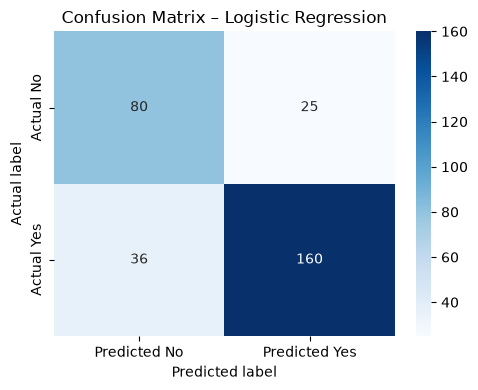

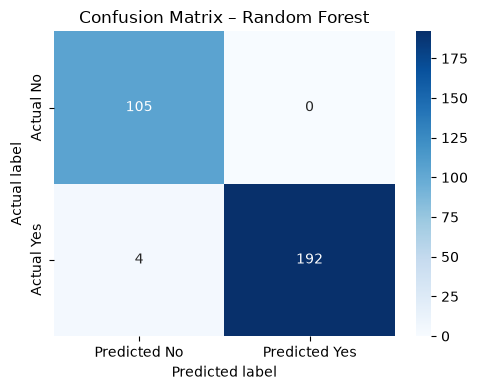

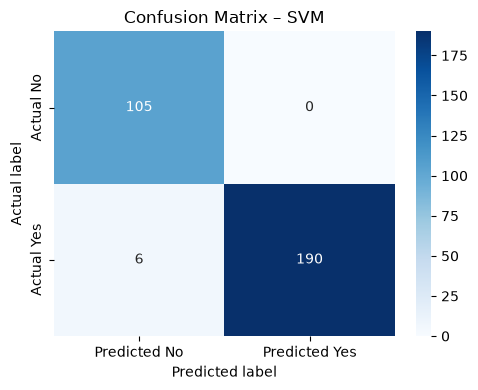

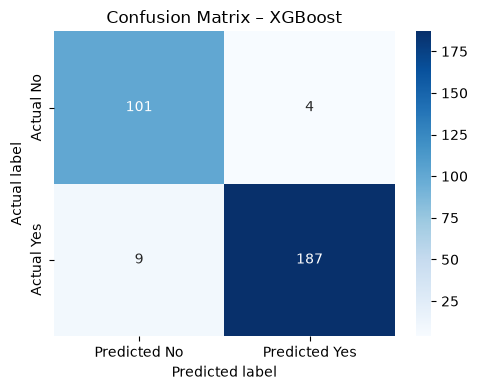

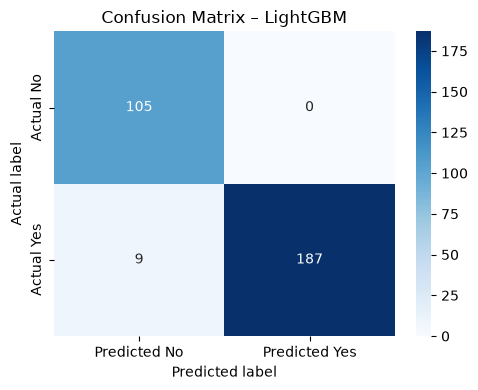

In [9]:
for model_name, values in test_predictions.items():
    cm = confusion_matrix(y_test, values["y_pred"], labels=[0, 1])

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted No", "Predicted Yes"],
        yticklabels=["Actual No", "Actual Yes"], ax=ax
    )
    ax.set_title(f"Confusion Matrix – {model_name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
    plt.tight_layout()
    safe_name = model_name.lower().replace(" ", "_")
    fig.savefig(GRAPHS_DIR / f"confusion_matrix_{safe_name}.png", dpi=300)
    plt.show()

ROC and precision-recall curves

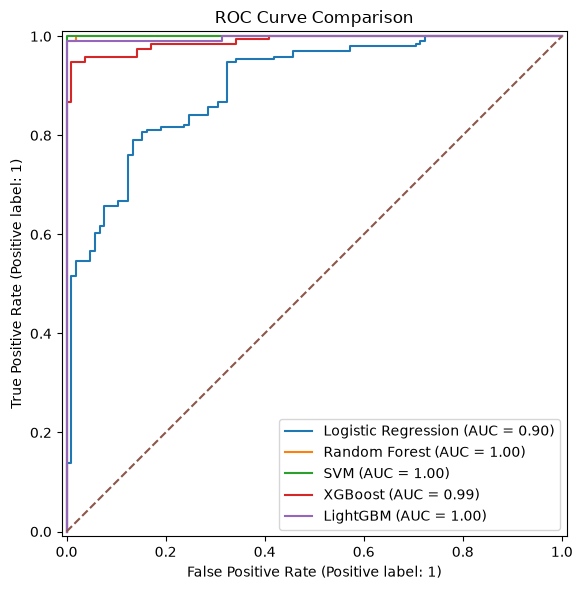

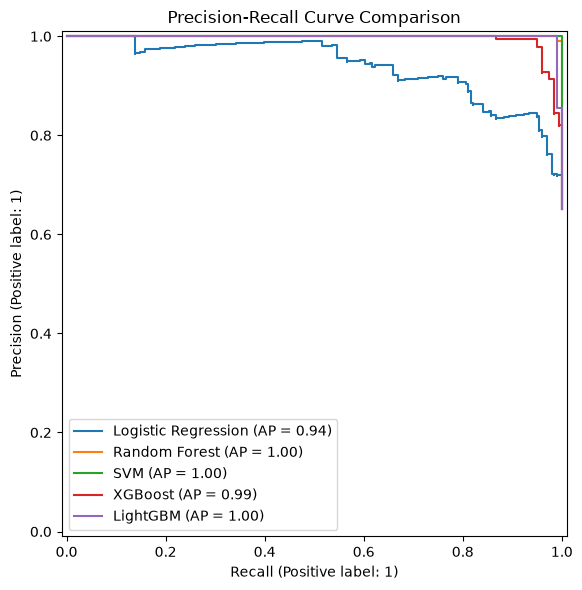

In [10]:
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, values in test_predictions.items():
    RocCurveDisplay.from_predictions(
        y_test, values["y_prob"], name=model_name, ax=ax
    )
ax.plot([0, 1], [0, 1], linestyle="--", label="Chance")
ax.set_title("ROC Curve Comparison")
plt.tight_layout()
fig.savefig(GRAPHS_DIR / "roc_curve_comparison.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(7, 6))
for model_name, values in test_predictions.items():
    PrecisionRecallDisplay.from_predictions(
        y_test, values["y_prob"], name=model_name, ax=ax
    )
ax.set_title("Precision-Recall Curve Comparison")
plt.tight_layout()
fig.savefig(GRAPHS_DIR / "precision_recall_comparison.png", dpi=300)
plt.show()

Calibration curves

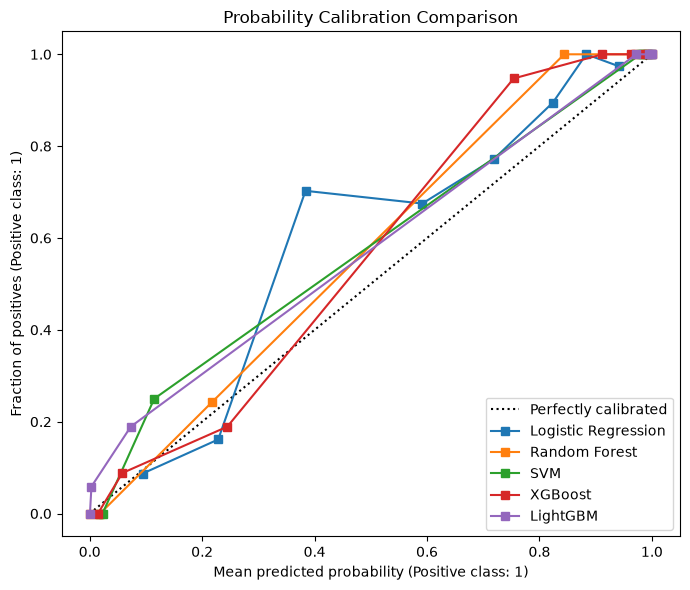

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
for model_name, values in test_predictions.items():
    CalibrationDisplay.from_predictions(
        y_test,
        values["y_prob"],
        n_bins=8,
        strategy="quantile",
        name=model_name,
        ax=ax
    )
ax.set_title("Probability Calibration Comparison")
plt.tight_layout()
fig.savefig(GRAPHS_DIR / "calibration_curve_comparison.png", dpi=300)
plt.show()

Select and save a candidate model

In [12]:
SELECTION_METRIC = "PR-AUC (Average Precision)"
best_model_name = evaluation_df.iloc[0]["Model"]
best_model = tuned_models[best_model_name]

print("Candidate model:", best_model_name)
print(evaluation_df.iloc[0].to_dict())

joblib.dump(best_model, MODEL_DIR / "best_ppd_model.joblib")

metadata = {
    "model_name": best_model_name,
    "selection_metric": SELECTION_METRIC,
    "target_column": TARGET_COLUMN,
    "target_mapping": TARGET_MAPPING,
    "input_features": X_test.columns.tolist(),
    "positive_class": 1,
    "warning": (
        "The current target is Feeling anxious, a symptom proxy. "
        "This model is not a validated PPD screening or diagnostic model."
    )
}
with open(MODEL_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)

print("Saved candidate model and metadata.")

Candidate model: SVM
{'Model': 'SVM', 'Accuracy': 0.9800664451827242, 'Precision': 1.0, 'Recall': 0.9693877551020408, 'F1 Score': 0.9844559585492227, 'ROC-AUC': 1.0, 'PR-AUC (Average Precision)': 1.0, 'Brier Score': 0.012649571440696934}
Saved candidate model and metadata.
